# Futures Analysis - ETH + BTC Perpetuals

Context for option buyers. The futures market shows **where the leveraged crowd is trapped**. That tells you when a squeeze is likely - which is the catalyst an option buyer needs.

**Data:** Bybit v5 public API. No DB, no files, no keys.

Covers:

1. Snapshot: mark, index, basis, funding
2. Funding history + annualized carry
3. Open interest history
4. OI change vs price (trend confirmation)
5. Taker buy/sell flow (aggressor pressure)
6. Basis history (premium / discount)
7. Realized volatility
8. Liquidation levels proxy
9. **FINAL VERDICT** - directional bias
10. Takeaways for option buyers

## Setup

```
pip install requests pandas numpy matplotlib
```

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (12, 4)

BYBIT = 'https://api.bybit.com'
SYMBOLS = {'ETH': 'ETHUSDT', 'BTC': 'BTCUSDT'}
print('ready  mode = BYBIT')

ready  mode = BYBIT


## 1. Snapshot: mark, index, basis, funding

Bybit `/v5/market/tickers` returns everything: mark price, index price, funding rate, next funding time.

In [2]:
def fetch_ticker(symbol):
    r = requests.get(f'{BYBIT}/v5/market/tickers',
                     params={'category': 'linear', 'symbol': symbol}, timeout=15)
    r.raise_for_status()
    return r.json()['result']['list'][0]


snapshot = {}
for cur, sym in SYMBOLS.items():
    try:
        d = fetch_ticker(sym)
        mark    = float(d['markPrice'])
        index   = float(d['indexPrice'])
        funding = float(d['fundingRate']) * 100
        nf      = int(d['nextFundingTime'])
        basis   = (mark - index) / index * 100
        hours_to = (nf - time.time() * 1000) / 3_600_000
        snapshot[cur] = dict(mark=mark, index=index, funding=funding,
                             next_funding=nf, basis=basis, hours_to=hours_to)
        print(f'{cur}: mark={mark:.2f}  index={index:.2f}  '
              f'basis={basis:+.3f}%  funding={funding:+.4f}%  '
              f'next funding in {hours_to:.1f}h')
    except Exception as e:
        print(f'{cur}: failed - {e}')

ETH: mark=2363.27  index=2364.23  basis=-0.041%  funding=+0.0094%  next funding in 3.8h
BTC: mark=80565.71  index=80605.20  basis=-0.049%  funding=+0.0064%  next funding in 3.8h


## 2. Funding history

Funding is paid every 8h. Persistently positive funding means longs are crowded and paying shorts - the classic cash-and-carry setup.

In [3]:
def fetch_funding(symbol, limit=200):
    r = requests.get(f'{BYBIT}/v5/market/funding/history',
                     params={'category': 'linear', 'symbol': symbol,
                             'limit': limit}, timeout=15)
    r.raise_for_status()
    return r.json()['result']['list']


funding_hist = {}
for cur, sym in SYMBOLS.items():
    try:
        h = fetch_funding(sym)
        rows = [{'ts': pd.to_datetime(int(x['fundingRateTimestamp']), unit='ms'),
                 'rate_pct': float(x['fundingRate']) * 100}
                for x in h]
        df_h = pd.DataFrame(rows).sort_values('ts')
        funding_hist[cur] = df_h
        ann = df_h['rate_pct'].mean() * 3 * 365
        print(f'{cur}: {len(df_h)} records  '
              f'mean={df_h.rate_pct.mean():+.5f}%  '
              f'annualized={ann:+.2f}%')
    except Exception as e:
        print(f'{cur}: funding fetch failed - {e}')

ETH: 200 records  mean=+0.00408%  annualized=+4.46%
BTC: 200 records  mean=+0.00447%  annualized=+4.89%


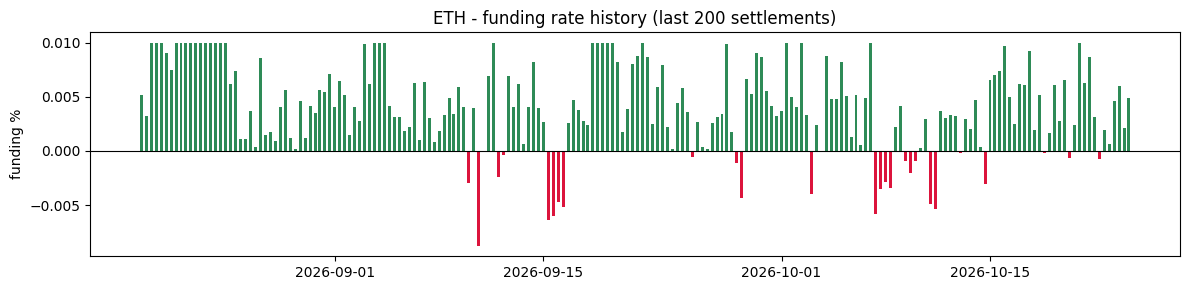

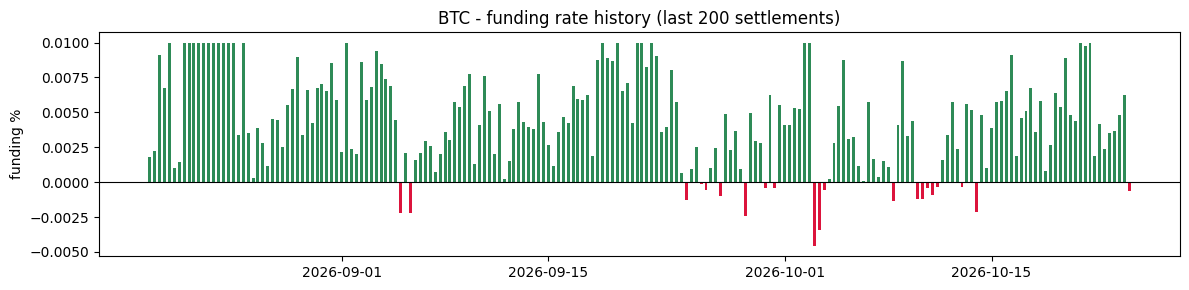

In [4]:
for cur, df_h in funding_hist.items():
    plt.figure(figsize=(12, 3))
    colors = ['seagreen' if x > 0 else 'crimson' for x in df_h.rate_pct]
    plt.bar(df_h.ts, df_h.rate_pct, color=colors, width=0.2)
    plt.title(f'{cur} - funding rate history (last {len(df_h)} settlements)')
    plt.ylabel('funding %')
    plt.axhline(0, color='black', lw=0.8)
    plt.tight_layout(); plt.show()

## 3. Open interest history

OI rising + price rising = real trend (new longs).
OI falling + price rising = short squeeze (weak rally).
OI rising + price falling = new shorts.
OI falling + price falling = long liquidation.

In [5]:
def fetch_oi(symbol, interval='1h', limit=200):
    r = requests.get(f'{BYBIT}/v5/market/open-interest',
                     params={'category': 'linear', 'symbol': symbol,
                             'intervalTime': interval, 'limit': limit}, timeout=15)
    r.raise_for_status()
    return r.json()['result']['list']


oi_hist = {}
for cur, sym in SYMBOLS.items():
    try:
        o = fetch_oi(sym, '1h', 200)
        rows = [{'ts': pd.to_datetime(int(x['timestamp']), unit='ms'),
                 'oi': float(x['openInterest'])}
                for x in o]
        df_o = pd.DataFrame(rows).sort_values('ts')
        oi_hist[cur] = df_o
        chg = (df_o.oi.iloc[-1] / df_o.oi.iloc[-24] - 1) * 100 if len(df_o) > 24 else 0
        print(f'{cur}: OI={df_o.oi.iloc[-1]:,.0f}  24h change={chg:+.2f}%')
    except Exception as e:
        print(f'{cur}: OI fetch failed - {e}')

ETH: OI=799,048  24h change=-0.71%
BTC: OI=64,042  24h change=+1.86%


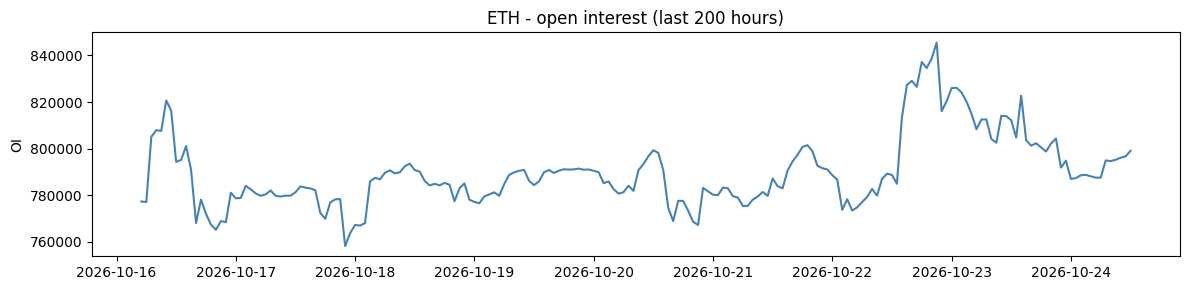

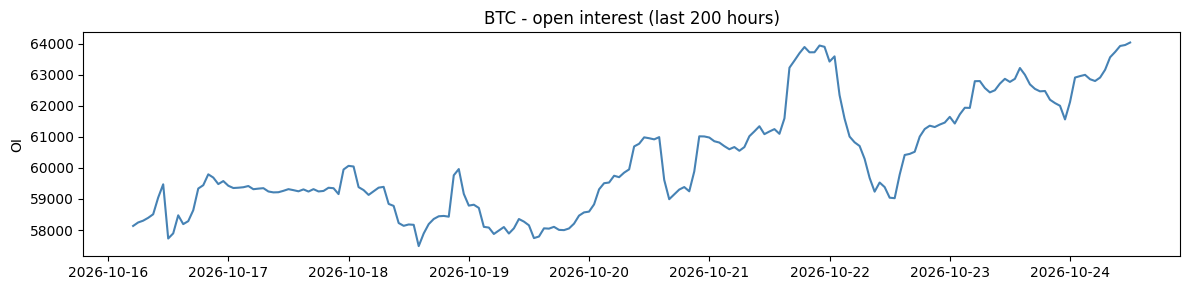

In [6]:
for cur, df_o in oi_hist.items():
    plt.figure(figsize=(12, 3))
    plt.plot(df_o.ts, df_o.oi, color='steelblue')
    plt.title(f'{cur} - open interest (last {len(df_o)} hours)')
    plt.ylabel('OI')
    plt.tight_layout(); plt.show()

## 4. Price history (klines)

In [7]:
def fetch_klines(symbol, interval='60', limit=200):
    r = requests.get(f'{BYBIT}/v5/market/kline',
                     params={'category': 'linear', 'symbol': symbol,
                             'interval': interval, 'limit': limit}, timeout=15)
    r.raise_for_status()
    return r.json()['result']['list']


price_hist = {}
for cur, sym in SYMBOLS.items():
    try:
        k = fetch_klines(sym, '60', 200)
        rows = [{'ts': pd.to_datetime(int(x[0]), unit='ms'),
                 'open': float(x[1]), 'high': float(x[2]),
                 'low': float(x[3]), 'close': float(x[4]),
                 'volume': float(x[5])} for x in k]
        df_k = pd.DataFrame(rows).sort_values('ts')
        price_hist[cur] = df_k
        print(f'{cur}: {len(df_k)} candles  last close={df_k.close.iloc[-1]:.2f}')
    except Exception as e:
        print(f'{cur}: klines failed - {e}')

ETH: 200 candles  last close=2363.28
BTC: 200 candles  last close=80564.60


## 5. Price + OI combined - is the trend real?

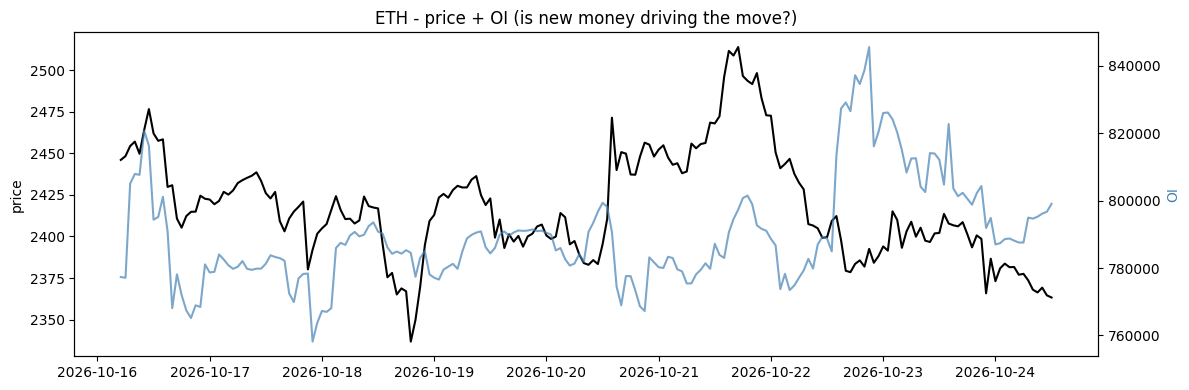

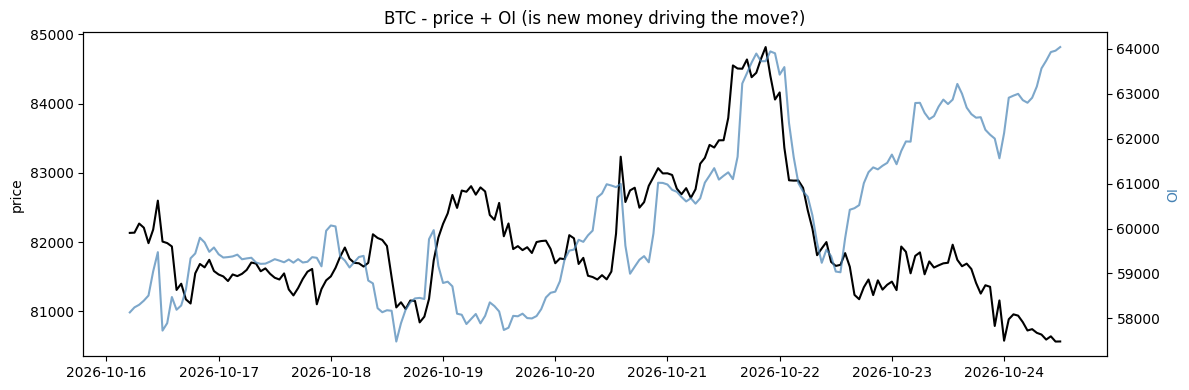

In [8]:
for cur in SYMBOLS:
    if cur not in price_hist or cur not in oi_hist: continue
    ph = price_hist[cur].tail(200).reset_index(drop=True)
    oh = oi_hist[cur].tail(200).reset_index(drop=True)
    n = min(len(ph), len(oh))
    fig, ax1 = plt.subplots(figsize=(12, 4))
    ax1.plot(ph.ts[-n:], ph.close[-n:], color='black', label='price')
    ax1.set_ylabel('price', color='black')
    ax2 = ax1.twinx()
    ax2.plot(oh.ts[-n:], oh.oi[-n:], color='steelblue', label='OI', alpha=0.7)
    ax2.set_ylabel('OI', color='steelblue')
    plt.title(f'{cur} - price + OI (is new money driving the move?)')
    plt.tight_layout(); plt.show()

## 6. Taker buy/sell flow

Aggressor pressure:

- > 1.0 = buyers hitting asks (bullish aggression)
- < 1.0 = sellers hitting bids (bearish aggression)

Bybit's recent trades endpoint lets us reconstruct this from the last N trades.

In [9]:
def fetch_recent_trades(symbol, limit=500):
    r = requests.get(f'{BYBIT}/v5/market/recent-trade',
                     params={'category': 'linear', 'symbol': symbol,
                             'limit': limit}, timeout=15)
    r.raise_for_status()
    return r.json()['result']['list']


taker_flow = {}
for cur, sym in SYMBOLS.items():
    try:
        trades = fetch_recent_trades(sym, 500)
        buys  = [t for t in trades if t['side'] == 'Buy']
        sells = [t for t in trades if t['side'] == 'Sell']
        buy_vol  = sum(float(t['size']) for t in buys)
        sell_vol = sum(float(t['size']) for t in sells)
        ratio = buy_vol / max(sell_vol, 1e-9)
        taker_flow[cur] = ratio
        label = 'buyers aggressive' if ratio > 1.1 else ('sellers aggressive' if ratio < 0.9 else 'balanced')
        print(f'{cur}: taker ratio={ratio:.3f}  ({label})  last {len(trades)} trades')
    except Exception as e:
        print(f'{cur}: taker fetch failed - {e}')

ETH: taker ratio=4.573  (buyers aggressive)  last 500 trades
BTC: taker ratio=1.262  (buyers aggressive)  last 500 trades


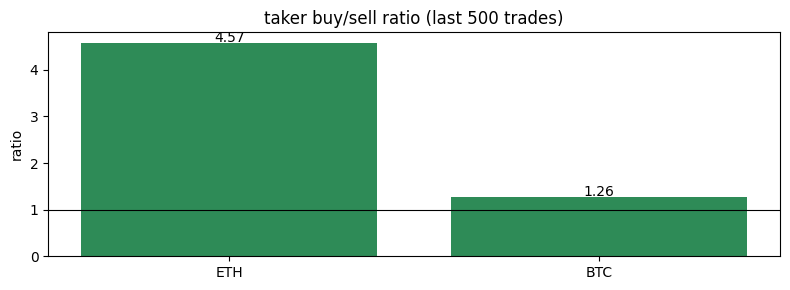

In [10]:
if taker_flow:
    plt.figure(figsize=(8, 3))
    bars = plt.bar(list(taker_flow.keys()), list(taker_flow.values()),
                   color=['seagreen' if v > 1 else 'crimson' for v in taker_flow.values()])
    plt.axhline(1.0, color='black', lw=0.8)
    plt.title('taker buy/sell ratio (last 500 trades)')
    plt.ylabel('ratio')
    for i, (k, v) in enumerate(taker_flow.items()):
        plt.text(i, v + 0.02, f'{v:.2f}', ha='center')
    plt.tight_layout(); plt.show()

## 7. Basis - premium or discount

Positive basis = perp above index (bullish crowd).
Negative = perp discount (bearish).

In [11]:
for cur in SYMBOLS:
    if cur not in snapshot: continue
    s = snapshot[cur]
    ann = s['basis'] * 365 * 24 * 100
    print(f'{cur}: mark={s["mark"]:.2f}  index={s["index"]:.2f}  '
          f'basis={s["basis"]:+.3f}%  ({ann:+.1f}% annualized)')

ETH: mark=2363.27  index=2364.23  basis=-0.041%  (-35570.1% annualized)
BTC: mark=80565.71  index=80605.20  basis=-0.049%  (-42916.9% annualized)


## 8. Realized volatility

In [12]:
for cur in SYMBOLS:
    if cur not in price_hist: continue
    c = price_hist[cur].close.values
    if len(c) < 30: continue
    r = np.diff(np.log(c))
    vol_24h = r[-24:].std() * np.sqrt(24*365) * 100
    vol_7d  = r[-168:].std() * np.sqrt(24*365) * 100 if len(r) >= 168 else float('nan')
    vol_all = r.std() * np.sqrt(24*365) * 100
    print(f'{cur}: 24h={vol_24h:.1f}%  7d={vol_7d:.1f}%  all={vol_all:.1f}%')

ETH: 24h=37.1%  7d=44.0%  all=42.4%
BTC: 24h=24.6%  7d=28.0%  all=27.4%


## 9. Liquidation clusters (proxy)

Typical leverage is 5x-10x, so liquidation clusters form around 5% and 10% moves from spot.

In [13]:
liq_levels = {}
for cur in SYMBOLS:
    if cur not in snapshot: continue
    spot = snapshot[cur]['index']
    liq_levels[cur] = dict(spot=spot,
                            longs_5=spot*0.95, longs_10=spot*0.90,
                            shorts_5=spot*1.05, shorts_10=spot*1.10)
    print(f'{cur}: spot={spot:.2f}')
    print(f'  long  liq cluster ~ {spot*0.95:.2f} (-5%)  {spot*0.90:.2f} (-10%)')
    print(f'  short liq cluster ~ {spot*1.05:.2f} (+5%)  {spot*1.10:.2f} (+10%)')

ETH: spot=2364.23
  long  liq cluster ~ 2246.02 (-5%)  2127.81 (-10%)
  short liq cluster ~ 2482.44 (+5%)  2600.65 (+10%)
BTC: spot=80605.20
  long  liq cluster ~ 76574.94 (-5%)  72544.68 (-10%)
  short liq cluster ~ 84635.46 (+5%)  88665.72 (+10%)


## 10. Composite signal scoring

Each signal votes LONG or SHORT. Majority wins.

In [14]:
verdicts = {}
for cur in SYMBOLS:
    if cur not in snapshot or cur not in oi_hist: continue
    s = snapshot[cur]
    fund  = s['funding']
    basis = s['basis']
    taker = taker_flow.get(cur, 1.0)
    oi    = oi_hist[cur].oi.values
    oi_chg = (oi[-1] / oi[-24] - 1) * 100 if len(oi) >= 24 else 0

    signals = []
    if fund > 0.02:    signals.append(('SHORT', 'funding very high (longs crowded)'))
    elif fund < -0.02: signals.append(('LONG',  'funding very negative (shorts crowded)'))
    if taker > 1.15:   signals.append(('LONG',  'taker flow strongly buy'))
    elif taker < 0.87: signals.append(('SHORT', 'taker flow strongly sell'))
    if oi_chg > 5 and basis > 0.1:
        signals.append(('LONG', 'OI up + basis positive (real demand)'))
    elif oi_chg > 5 and basis < -0.1:
        signals.append(('SHORT', 'OI up + basis negative (distribution)'))

    longs = sum(1 for s in signals if s[0] == 'LONG')
    shorts = sum(1 for s in signals if s[0] == 'SHORT')
    bias = 'LONG' if longs > shorts else ('SHORT' if shorts > longs else 'NEUTRAL')

    verdicts[cur] = dict(bias=bias, fund=fund, basis=basis, taker=taker,
                          oi_chg=oi_chg, signals=signals, longs=longs, shorts=shorts)

for cur, v in verdicts.items():
    print(f'\n{cur}: bias={v["bias"]}  ({v["longs"]} long / {v["shorts"]} short)')
    for d, why in v['signals']:
        print(f'  [{d:5}] {why}')


ETH: bias=LONG  (1 long / 0 short)
  [LONG ] taker flow strongly buy

BTC: bias=LONG  (1 long / 0 short)
  [LONG ] taker flow strongly buy


## 11. Funding carry opportunity

If funding is positive, you can short perp and hold spot to collect carry. This is the cash-and-carry trade.

In [15]:
for cur, v in verdicts.items():
    ann = v['fund'] * 3 * 365
    if ann > 5:
        print(f'{cur}: SHORT perp + LONG spot -> {ann:+.1f}% annualized')
    elif ann < -5:
        print(f'{cur}: LONG perp + SHORT spot -> {-ann:+.1f}% annualized')
    else:
        print(f'{cur}: funding {ann:+.1f}% annualized - carry not worth it')

ETH: SHORT perp + LONG spot -> +10.3% annualized
BTC: SHORT perp + LONG spot -> +7.0% annualized


## 12. Extreme funding warnings

In [16]:
for cur, v in verdicts.items():
    f = v['fund']
    if abs(f) > 0.05:
        print(f'WARN {cur}: funding {f:+.4f}% - extreme. Reversal risk high.')
    elif abs(f) > 0.03:
        print(f'NOTE {cur}: funding {f:+.4f}% - elevated. Watch.')
    else:
        print(f'OK   {cur}: funding {f:+.4f}% - normal.')

OK   ETH: funding +0.0094% - normal.
OK   BTC: funding +0.0064% - normal.


## 13. OI vs price divergence alert

In [17]:
for cur in SYMBOLS:
    if cur not in oi_hist or cur not in price_hist: continue
    o = oi_hist[cur].oi.values
    p = price_hist[cur].close.values
    n = min(len(o), len(p), 24)
    if n < 12: continue
    oi_chg = (o[-1] / o[-n] - 1) * 100
    px_chg = (p[-1] / p[-n] - 1) * 100
    print(f'{cur}: 24h price {px_chg:+.2f}%  OI {oi_chg:+.2f}%')
    if px_chg > 1 and oi_chg > 1:
        print('  -> healthy uptrend (new money driving)')
    elif px_chg > 1 and oi_chg < -1:
        print('  -> short squeeze (weak rally, avoid buying calls)')
    elif px_chg < -1 and oi_chg > 1:
        print('  -> healthy downtrend (new shorts driving)')
    elif px_chg < -1 and oi_chg < -1:
        print('  -> long liquidation (weak drop, avoid buying puts)')

ETH: 24h price -2.08%  OI -0.71%
BTC: 24h price -1.70%  OI +1.86%
  -> healthy downtrend (new shorts driving)


## 14. FINAL VERDICT

In [18]:
print('=' * 70)
print('FUTURES VERDICT')
print('=' * 70)

for cur, v in verdicts.items():
    s = snapshot[cur]
    print(f'\n{cur}  (mark {s["mark"]:.2f})')
    print(f'  Funding       : {v["fund"]:+.4f}%  (annualized {v["fund"]*3*365:+.1f}%)')
    print(f'  Basis         : {v["basis"]:+.3f}%')
    print(f'  OI 24h change : {v["oi_chg"]:+.2f}%')
    print(f'  Taker ratio   : {v["taker"]:.3f}')
    print(f'  Signal count  : {v["longs"]} long / {v["shorts"]} short')
    print(f'  Bias          : {v["bias"]}')

FUTURES VERDICT

ETH  (mark 2363.27)
  Funding       : +0.0094%  (annualized +10.3%)
  Basis         : -0.041%
  OI 24h change : -0.71%
  Taker ratio   : 4.573
  Signal count  : 1 long / 0 short
  Bias          : LONG

BTC  (mark 80565.71)
  Funding       : +0.0064%  (annualized +7.0%)
  Basis         : -0.049%
  OI 24h change : +1.86%
  Taker ratio   : 1.262
  Signal count  : 1 long / 0 short
  Bias          : LONG


## 15. What this means for an option buyer

In [19]:
print('=' * 70)
print('OPTION BUYER TAKEAWAYS')
print('=' * 70)

for cur, v in verdicts.items():
    print(f'\n{cur}:')
    if v['bias'] == 'LONG':
        print('  -> Futures crowd is short/trapped. Buy CALLS on dips.')
        print('  -> Short squeeze can fuel a fast move higher.')
    elif v['bias'] == 'SHORT':
        print('  -> Futures crowd is long/trapped. Buy PUTS on rallies.')
        print('  -> Long squeeze can fuel a fast move lower.')
    else:
        print('  -> No futures edge. Wait for a clearer signal.')
    if abs(v['fund']) > 0.03:
        print(f'  -> Funding {v["fund"]:+.3f}% is elevated - beware reversal.')
    if v['oi_chg'] < -3 and abs(v['basis']) < 0.1:
        print('  -> OI falling + basis flat - noise, not trend.')

OPTION BUYER TAKEAWAYS

ETH:
  -> Futures crowd is short/trapped. Buy CALLS on dips.
  -> Short squeeze can fuel a fast move higher.

BTC:
  -> Futures crowd is short/trapped. Buy CALLS on dips.
  -> Short squeeze can fuel a fast move higher.


## 16. Summary table

In [20]:
summary = pd.DataFrame([
    {'pair': cur,
     'mark': snapshot[cur]['mark'],
     'basis_pct': snapshot[cur]['basis'],
     'funding_pct': v['fund'],
     'funding_ann': v['fund'] * 3 * 365,
     'taker': v['taker'],
     'oi_chg_24h': v['oi_chg'],
     'bias': v['bias']}
    for cur, v in verdicts.items()
])
print(summary.to_string(index=False))

pair     mark  basis_pct  funding_pct  funding_ann    taker  oi_chg_24h bias
 ETH  2363.27  -0.040605     0.009373    10.263435 4.573374   -0.707289 LONG
 BTC 80565.71  -0.048992     0.006381     6.987195 1.262289    1.861738 LONG


## Notes on the data source

All endpoints are **Bybit v5 public market data**. No API key required.

| Endpoint | What it returns |
|---|---|
| `/v5/market/tickers` | Mark, index, funding rate, next funding time |
| `/v5/market/funding/history` | Historical funding settlements |
| `/v5/market/open-interest` | OI snapshots over time |
| `/v5/market/kline` | OHLCV candles |
| `/v5/market/recent-trade` | Recent trades (for taker flow) |

**Bybit does not expose public long/short ratio endpoints.** If you need that signal, add an OKX section (`/api/v5/rubik/stat/contracts/long-short-account-ratio`).

In [21]:
print('-' * 70)
print('Done. Data is live from Bybit - rerun to refresh.')
print(f'Generated at {datetime.now(timezone.utc):%Y-%m-%d %H:%M:%S} UTC')

----------------------------------------------------------------------
Done. Data is live from Bybit - rerun to refresh.
Generated at 2026-10-24 12:10:44 UTC
